# 01 - Seismic modelling, with HDF5 output

This is the SLIM *Devito-Examples* tutorial
[01 - Introduction to seismic modelling](https://slimgroup.github.io/Devito-Examples/tutorials/01_modelling/),
with one addition: the wavefield and everything needed to interpret it are
written to a single self-describing **HDF5** file.

The physics and the numbers are untouched - the shot-record check at the end is
still the original `assert`. What is new is `devito_hdf5.py`, which provides:

| | |
|---|---|
| `SnapshotRecorder` | records *N* evenly spaced wavefield snapshots **inside** the time loop |
| `export_hdf5` | writes model, geometry, snapshots and shot record to one file |
| `load_hdf5` / `summarize_hdf5` | read it back / print its structure |

The recorder uses a Devito `ConditionalDimension`, so the memory cost is
`O(nsnaps)` rather than `O(nt)`. On this problem, saving every step would cost
410 x 121 x 121 x 4 B = 24 MB; 50 snapshots cost 2.9 MB. On a 3D FWI-sized run
that difference is the one between fitting in RAM and not.

**The same two calls work in every other tutorial** - acoustic, TTI, elastic,
viscoelastic - including the staggered vector/tensor fields of the elastic
cases. The last section shows how.

In [1]:
# NBVAL_IGNORE_OUTPUT
import sys, os
sys.path.insert(0, os.getcwd())   # so that devito_hdf5.py is importable

import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt

from qpdesolver.generator.devito_hdf5 import (SnapshotRecorder, export_hdf5,
                         load_hdf5, summarize_hdf5)

## 1. The velocity model

Unchanged from the original: a 1 km x 1 km domain on a 101 x 101 grid, two
layers at 1.5 and 2.5 km/s, and a 10-point absorbing layer (`nbl=10`) so the
edges do not reflect.

Operator `initdamp` ran in 0.01 s


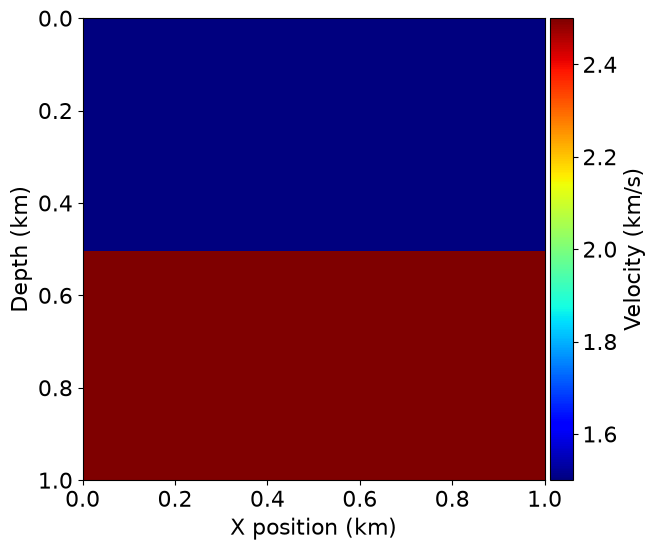

In [2]:
# NBVAL_IGNORE_OUTPUT
from examples.seismic import Model, plot_velocity

shape = (101, 101)      # Number of grid points (nx, nz)
spacing = (10., 10.)    # Grid spacing in m -> 1 km x 1 km domain
origin = (0., 0.)       # Top-left corner, so source/receiver coords are absolute

v = np.empty(shape, dtype=np.float32)
v[:, :51] = 1.5
v[:, 51:] = 2.5

model = Model(vp=v, origin=origin, shape=shape, spacing=spacing,
              space_order=2, nbl=10, bcs="damp")

plot_velocity(model)

## 2. Time axis

`model.critical_dt` is the largest step the CFL condition allows for this
grid and velocity.

In [3]:
from examples.seismic import TimeAxis

t0 = 0.     # Simulation starts at t = 0
tn = 1000.  # ... and lasts 1 s (1000 ms)
dt = model.critical_dt

time_range = TimeAxis(start=t0, stop=tn, step=dt)
print(time_range)
print("nt = %d time steps of %.4f ms" % (time_range.num, dt))

TimeAxis: start=0, stop=1001.64, step=2.449, num=410
nt = 410 time steps of 2.4490 ms


## 3. Source: a 10 Hz Ricker wavelet

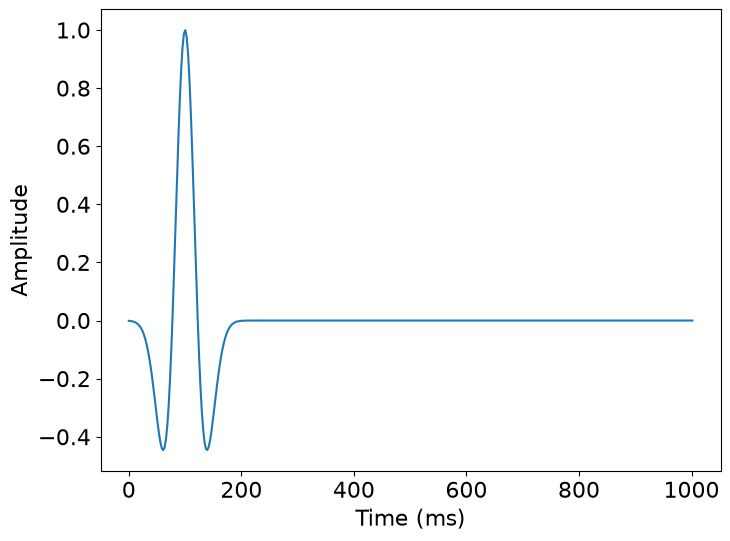

In [4]:
# NBVAL_IGNORE_OUTPUT
from examples.seismic import RickerSource

f0 = 0.010   # 10 Hz, expressed in kHz
src = RickerSource(name='src', grid=model.grid, f0=f0,
                   npoint=1, time_range=time_range)

src.coordinates.data[0, :] = np.array(model.domain_size) * .5
src.coordinates.data[0, -1] = 20.   # 20 m deep

src.show()

## 4. Receivers: 101 of them, 20 m deep

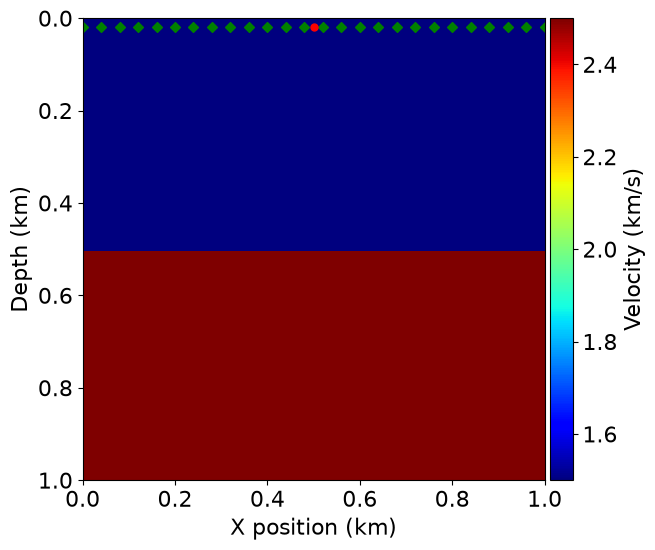

In [5]:
# NBVAL_IGNORE_OUTPUT
from examples.seismic import Receiver

rec = Receiver(name='rec', grid=model.grid, npoint=101, time_range=time_range)
rec.coordinates.data[:, 0] = np.linspace(0, model.domain_size[0], num=101)
rec.coordinates.data[:, 1] = 20.

plot_velocity(model, source=src.coordinates.data,
              receiver=rec.coordinates.data[::4, :])

## 5. The discretised wave equation

$$m\,\frac{\partial^2 u}{\partial t^2} - \nabla^2 u + \eta\,\frac{\partial u}{\partial t} = 0$$

with $m = 1/c^2$ the square slowness and $\eta$ the damping profile of the
absorbing layer.

In [6]:
from devito import TimeFunction, Eq, solve

u = TimeFunction(name="u", grid=model.grid, time_order=2, space_order=2)

pde = model.m * u.dt2 - u.laplace + model.damp * u.dt
stencil = Eq(u.forward, solve(pde, u.forward))
stencil

Eq(u(t + dt, x, y), (-(-2.0*u(t, x, y)/dt**2 + u(t - dt, x, y)/dt**2)/vp(x, y)**2 + Derivative(u(t, x, y), (x, 2)) + Derivative(u(t, x, y), (y, 2)) + damp(x, y)*u(t, x, y)/dt)/(damp(x, y)/dt + 1/(dt**2*vp(x, y)**2)))

In [7]:
src_term = src.inject(field=u.forward, expr=src * dt**2 / model.m)
rec_term = rec.interpolate(expr=u.forward)

## 6. NEW - set up snapshot recording

`SnapshotRecorder` builds a `ConditionalDimension` that fires every `factor`
time steps, plus one shadow `TimeFunction` per field sized exactly to the
number of snapshots. You append `snap.equations` to the operator; the stencil
itself does not change.

**On choosing `nsnaps`.** The hard limit is `nsnaps <= nt` - you cannot save
more snapshots than the solution has time steps, and asking for more raises a
`ValueError`. Beyond that, the stride has to be a whole number of steps, so the
achievable count is `ceil(nt / ceil(nt / nsnaps))`. The recorder rounds
*down* (never allocating more memory than you asked for) and warns when the
number it can deliver differs from the number you requested. Ask for a divisor
of `nt` if you want an exact count.

In [8]:
# NBVAL_IGNORE_OUTPUT
NSNAPS = 50          # <-- the one knob; must be <= time_range.num

snap = SnapshotRecorder(u, nt=time_range.num, nsnaps=NSNAPS)
print(snap)
print("recording every %d steps, at time-step indices %s ..." % (snap.factor, snap.indices[:6]))
print("memory: %.1f MB  (saving every step would be %.1f MB)"
      % (snap.nsnaps * np.prod(model.grid.shape) * 4 / 1e6,
         time_range.num * np.prod(model.grid.shape) * 4 / 1e6))

<SnapshotRecorder ['u']  nsnaps=46 (requested 50)  factor=9  nt=410>
recording every 9 steps, at time-step indices [ 0  9 18 27 36 45] ...
memory: 2.7 MB  (saving every step would be 24.0 MB)


/tmp/ipykernel_419/289191593.py:4: UserWarning: nsnaps=50 is not reachable with an integer stride over 410 time steps; recording 46 snapshots every 9 steps instead. Use a divisor of 410 (or pass factor=...) for an exact count.
  snap = SnapshotRecorder(u, nt=time_range.num, nsnaps=NSNAPS)


Guard rails, if you want to see them fire:

```python
SnapshotRecorder(u, nt=time_range.num, nsnaps=time_range.num + 1)
# ValueError: nsnaps=411 exceeds the number of time steps nt=410 ...
```

## 7. Build and run the operator

The only change from the original is `+ snap.equations`.

In [9]:
# NBVAL_IGNORE_OUTPUT
from devito import Operator

op = Operator([stencil] + src_term + rec_term + snap.equations,
              subs=model.spacing_map)

In [10]:
# NBVAL_IGNORE_OUTPUT
op(time=time_range.num - 1, dt=model.critical_dt)

Operator `Kernel` ran in 0.01 s


PerformanceSummary([(PerfKey(name='section0', rank=None),
                     PerfEntry(time=0.0028910000000000042, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[])),
                    (PerfKey(name='section1', rank=None),
                     PerfEntry(time=2.900000000000001e-05, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[])),
                    (PerfKey(name='section2', rank=None),
                     PerfEntry(time=0.00043400000000000345, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[])),
                    (PerfKey(name='section3', rank=None),
                     PerfEntry(time=0.00038999999999999994, gflopss=0.0, gpointss=0.0, oi=0.0, ops=0, itershapes=[]))])

## 8. The shot record - unchanged

Proof that adding the recorder did not perturb the simulation: this is the
original tutorial's own check.

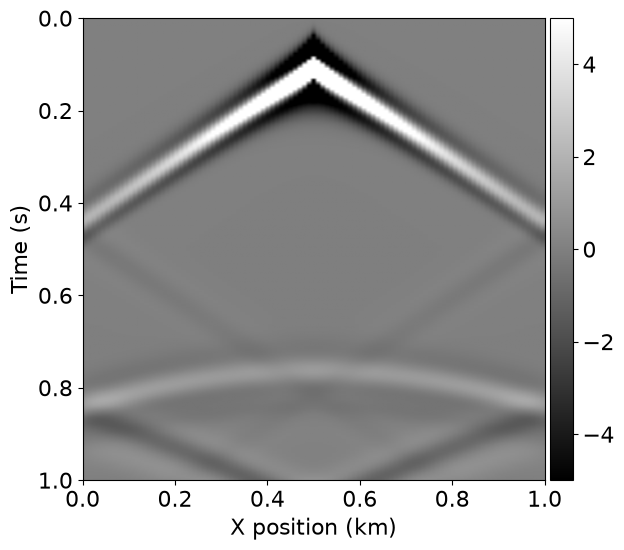

In [11]:
# NBVAL_IGNORE_OUTPUT
from examples.seismic import plot_shotrecord

plot_shotrecord(rec.data, model, t0, tn)

In [12]:
print("||rec.data|| =", np.linalg.norm(rec.data))
assert np.isclose(np.linalg.norm(rec.data), 370, rtol=1)

||rec.data|| = 370.03995


## 9. NEW - write everything to HDF5

Every argument but the filename is optional, so this call shrinks or grows with
what your run actually produced.

`strip_nbl=True` removes the absorbing layer, so the arrays in the file match
the 101 x 101 physical domain rather than the 121 x 121 computational grid.

Note `fields={'u_final': u}`: with an integer stride the last snapshot does not
generally land on the last time step, so if you want the end state exactly,
store it explicitly.

In [13]:
OUT = "tutorial01_modelling.h5"

export_hdf5(OUT,
            model=model,
            time_range=time_range,
            snapshots=snap,
            sources={'src': src},
            receivers={'rec': rec},
            fields={'u_final': u},          # exact final wavefield
            strip_nbl=True,                 # drop the absorbing layer
            compression="gzip",
            attrs={'tutorial': '01_modelling',
                   'physics': 'isotropic acoustic, 2nd order'})

print("wrote %s  (%.2f MB)" % (OUT, os.path.getsize(OUT) / 1024**2))

wrote tutorial01_modelling.h5  (1.57 MB)


## 10. What is in the file

Self-describing: shapes, units, layouts and the Devito version are all stored as
attributes, so the file is still interpretable without this notebook.

In [14]:
# NBVAL_IGNORE_OUTPUT
summarize_hdf5(OUT)

tutorial01_modelling.h5  (1.57 MB)
    @absorbing_layer_stripped   True
    @created                    2026-10-19T17:50:05.732089+01:00
    @devito_version             4.8.23
    @format                     devito-seismic-hdf5
    @format_version             1.0
    @numpy_version              2.4.3
    @physics                    isotropic acoustic, 2nd order
    @tutorial                   01_modelling
  coords/
    x                    (101,)             float64
        @description            physical x axis
        @units                  m
    y                    (101,)             float64
        @description            physical y axis
        @units                  m
  fields/
    u                    (46, 101, 101)     float32
        @description            wavefield snapshots of u
        @layout                 (snapshot, x, y)
        @staggered              []
  final_fields/
    u_final              (101, 101)         float32
        @description            field u_fi

## 11. Read it back and check the round trip

In [15]:
# NBVAL_IGNORE_OUTPUT
d = load_hdf5(OUT)

U     = d['fields']['u']                 # (nsnaps, nx, nz)
times = d['time']['snapshot_time']       # ms
shot  = d['geometry']['rec']['data']     # (nt, nrec)

print("snapshots :", U.shape, U.dtype)
print("times     : %.1f ... %.1f ms" % (times[0], times[-1]))
print("shot record:", shot.shape)

# round trip must be exact (no lossy compression involved)
assert np.array_equal(shot, rec.data), "shot record changed on round trip"
assert np.allclose(U[-1], snap.arrays(nbl=model.nbl)['u'][-1])
print("\nround trip exact.")

snapshots : (46, 101, 101) float32
times     : 0.0 ... 991.8 ms
shot record: (410, 101)

round trip exact.


## 12. The wavefield, straight from the file

A montage of snapshots, all on one shared symmetric colour scale so the panels
are comparable with each other. You can see the wavefront reach the interface at
500 m, split into a reflection and a transmission, and the absorbing layer eat
the energy that reaches the edges.

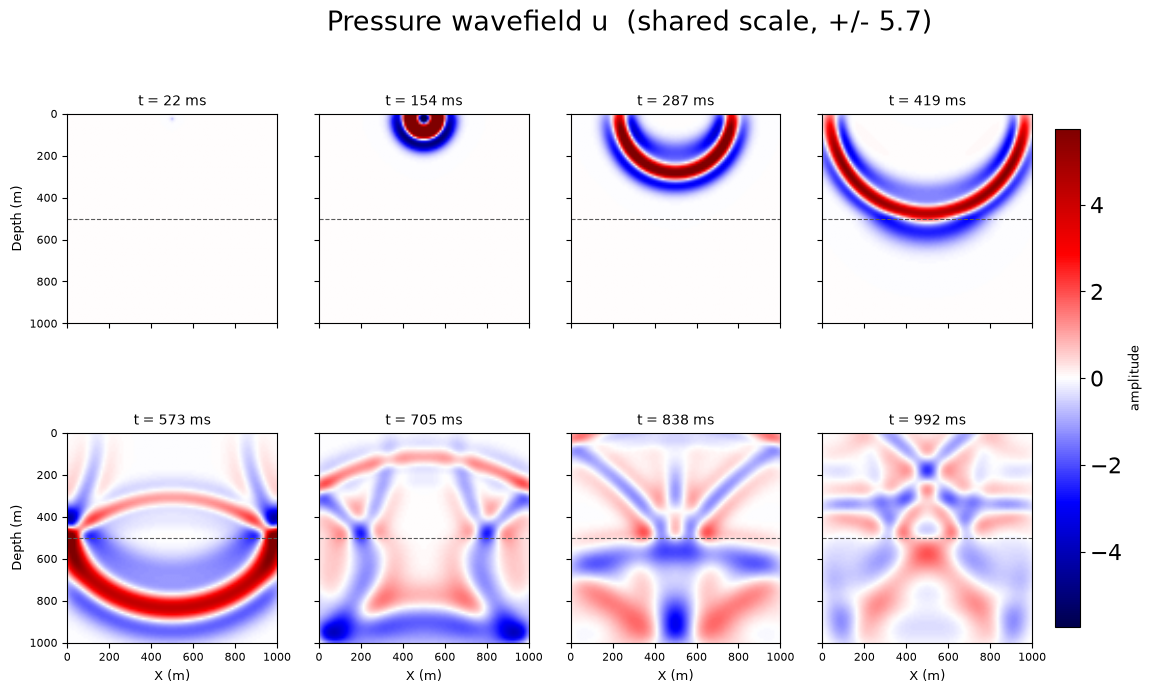

In [16]:
# NBVAL_IGNORE_OUTPUT
picks = np.linspace(1, len(U) - 1, 8).astype(int)

# one shared, symmetric scale: diverging data must be centred on zero, and a
# shared range is what makes small multiples comparable.
lim = np.percentile(np.abs(U[picks]), 99.5)

extent = [0, model.domain_size[0], model.domain_size[1], 0]
fig, axes = plt.subplots(2, 4, figsize=(15, 7.6), sharex=True, sharey=True)
for ax, k in zip(axes.ravel(), picks):
    im = ax.imshow(U[k].T, cmap="seismic", vmin=-lim, vmax=lim,
                   extent=extent, interpolation="bilinear")
    ax.axhline(500, color="0.35", lw=0.8, ls="--")      # the interface
    ax.set_title("t = %.0f ms" % times[k], fontsize=10)
    ax.tick_params(labelsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("Depth (m)", fontsize=9)
for ax in axes[-1, :]:
    ax.set_xlabel("X (m)", fontsize=9)

fig.suptitle("Pressure wavefield u  (shared scale, +/- %.2g)" % lim, y=0.98)
fig.subplots_adjust(right=0.9)
cb = fig.colorbar(im, ax=axes, shrink=0.85, pad=0.02)
cb.set_label("amplitude", fontsize=9)
plt.show()

A single trace through the snapshot stack is a cheap sanity check that the
recorded times really are the times the file claims.

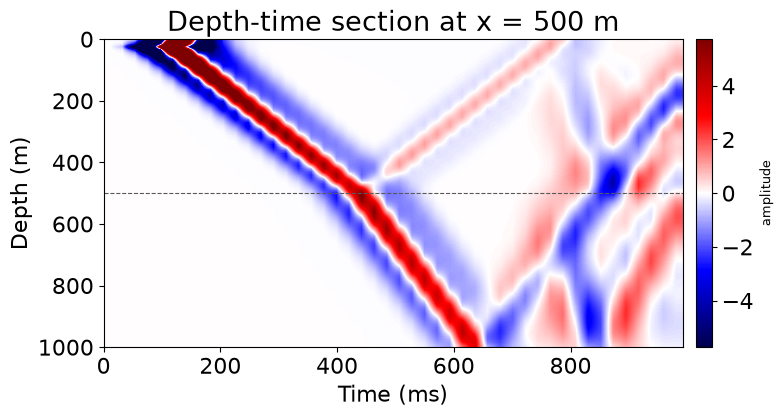

In [17]:
# NBVAL_IGNORE_OUTPUT
ix = U.shape[1] // 2          # vertical line through the source
fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(U[:, ix, :].T, cmap="seismic", vmin=-lim, vmax=lim,
               aspect="auto", interpolation="bilinear",
               extent=[times[0], times[-1], model.domain_size[1], 0])
ax.axhline(500, color="0.35", lw=0.8, ls="--")
ax.set_xlabel("Time (ms)"); ax.set_ylabel("Depth (m)")
ax.set_title("Depth-time section at x = %.0f m" % (ix * spacing[0]))
fig.colorbar(im, ax=ax, pad=0.02).set_label("amplitude", fontsize=9)
plt.show()

## 13. Using this in the other tutorials

Nothing above is specific to the acoustic case. `SnapshotRecorder` accepts a
single `TimeFunction`, a list, a dict, or Devito's composite
`VectorTimeFunction` / `TensorTimeFunction` - composites are expanded into their
scalar components, symmetric tensors are stored once per unique component, and
each shadow buffer inherits the staggering of the field it shadows.

**Elastic (tutorial 06)** - `v` is a vector, `tau` a symmetric tensor:

```python
snap = SnapshotRecorder({'v': v, 'tau': tau}, nt=time_range.num, nsnaps=20)
# -> v_x, v_y, tau_xx, tau_xy, tau_yy    (5 buffers, staggering preserved)

op = Operator([u_v, u_t] + src_xx + src_zz + rec_term + snap.equations,
              subs=model.spacing_map)
op(dt=dt, time=time_range.num - 1)

export_hdf5("tutorial06_elastic.h5", model=model, time_range=time_range,
            snapshots=snap, sources={'src': src}, receivers={'rec': rec},
            attrs={'tutorial': '06_elastic'})
# model/ then contains lam, mu, b instead of vp
```

**TTI (tutorial on anisotropy)** - two coupled wavefields:

```python
snap = SnapshotRecorder({'u': u, 'v': v}, nt=time_range.num, nsnaps=40)
```

**RTM / FWI (tutorials 02, 03)** - snapshot the adjoint field too, and store
gradients as ordinary fields:

```python
snap = SnapshotRecorder(v_adj, nt=time_range.num, nsnaps=30)
export_hdf5("rtm.h5", model=model, time_range=time_range, snapshots=snap,
            fields={'image': image}, receivers={'rec': rec})
```

**Post-hoc, with no recorder at all** - if you already have a stack of
wavefields in memory (say from `TimeFunction(..., save=nt)`), pass a plain
dict; the first axis is taken as time:

```python
export_hdf5("out.h5", model=model, time_range=time_range,
            snapshots={'u': u_saved.data[::10]})
```

Three details worth knowing when you start changing things:

- **`record='forward'`** snapshots `u.forward` instead of `u`, if you want the
  field after the update rather than before.
- **`strip_nbl=False`** keeps the absorbing layer, which you want when
  debugging the damping profile itself.
- **`dtype=None`** disables the cast to `float32` and stores whatever precision
  the run used.